In [1]:
source('../../../R/preamble.R')

freqplot = function(df, spacing = 0.0){
    ggplot(df) + aes(gen, freq + spacing*dense_rank(pos), col = pos, group = paste0(ref, pos, alt, wave)) + 
    geom_line(linewidth = 0.1) + geom_point(size = 0.3) +
    facet_wrap(~pop, ncol = 4) +
    labs(x = 'Timepoint', y = 'Frequency')
    }

fp = function(df, alpha = 0.4){
    ggplot(df) + aes(gen, freq, col = pos, group = paste0(ref, pos, alt, wave)) + 
    geom_line(linewidth = 0.1, alpha = alpha) +
    facet_wrap(~pop, ncol = 4) +
    labs(x = 'Timepoint', y = 'Frequency')
    }


size(4, 8)
options(repr.matrix.max.cols=150)

# Some mutations of interests to check
muts = 2859179
mutl = 4397612
rpsg = 3473612
nrda = 2345696

last_timepoint = 24

In [2]:
d = read.tsv('../../../datasets/genomics/03_variant_filtering/intermediate/d_complete.tsv')

# Singletons
Some variants appear at one gen and disappear at the next. It could be that:
* They are beneficial, so they often rise to detectable concentrations
* They are common sequencing errors, so they appear sporadically

Policy: keep a variant if it either:
* Goes above 0.5
* Appears less than 5 times and has positive autocorrelation of presence
* At some point it is detected on >=4 reads out of >=30 reads

There is also a spike of variants that show up in small amount at timepoint 13, in every generation.
I don't know why this happened, but it's almost certainly some mistake specific to that series of samples.

Warning message:
“There were 46 warnings in `mutate()`.
The first warning was:
ℹ In argument: `autocor = ifelse(sum(present) > 1, cor(present, already_there),
  1)`.
ℹ In group 247: `chrom = "U00096"`, `pos = 72059`, `ref = "C"`, `alt = "A"`.
Caused by warning in `cor()`:
! the standard deviation is zero
ℹ Run `dplyr::last_dplyr_warnings()` to see the 45 remaining warnings.”


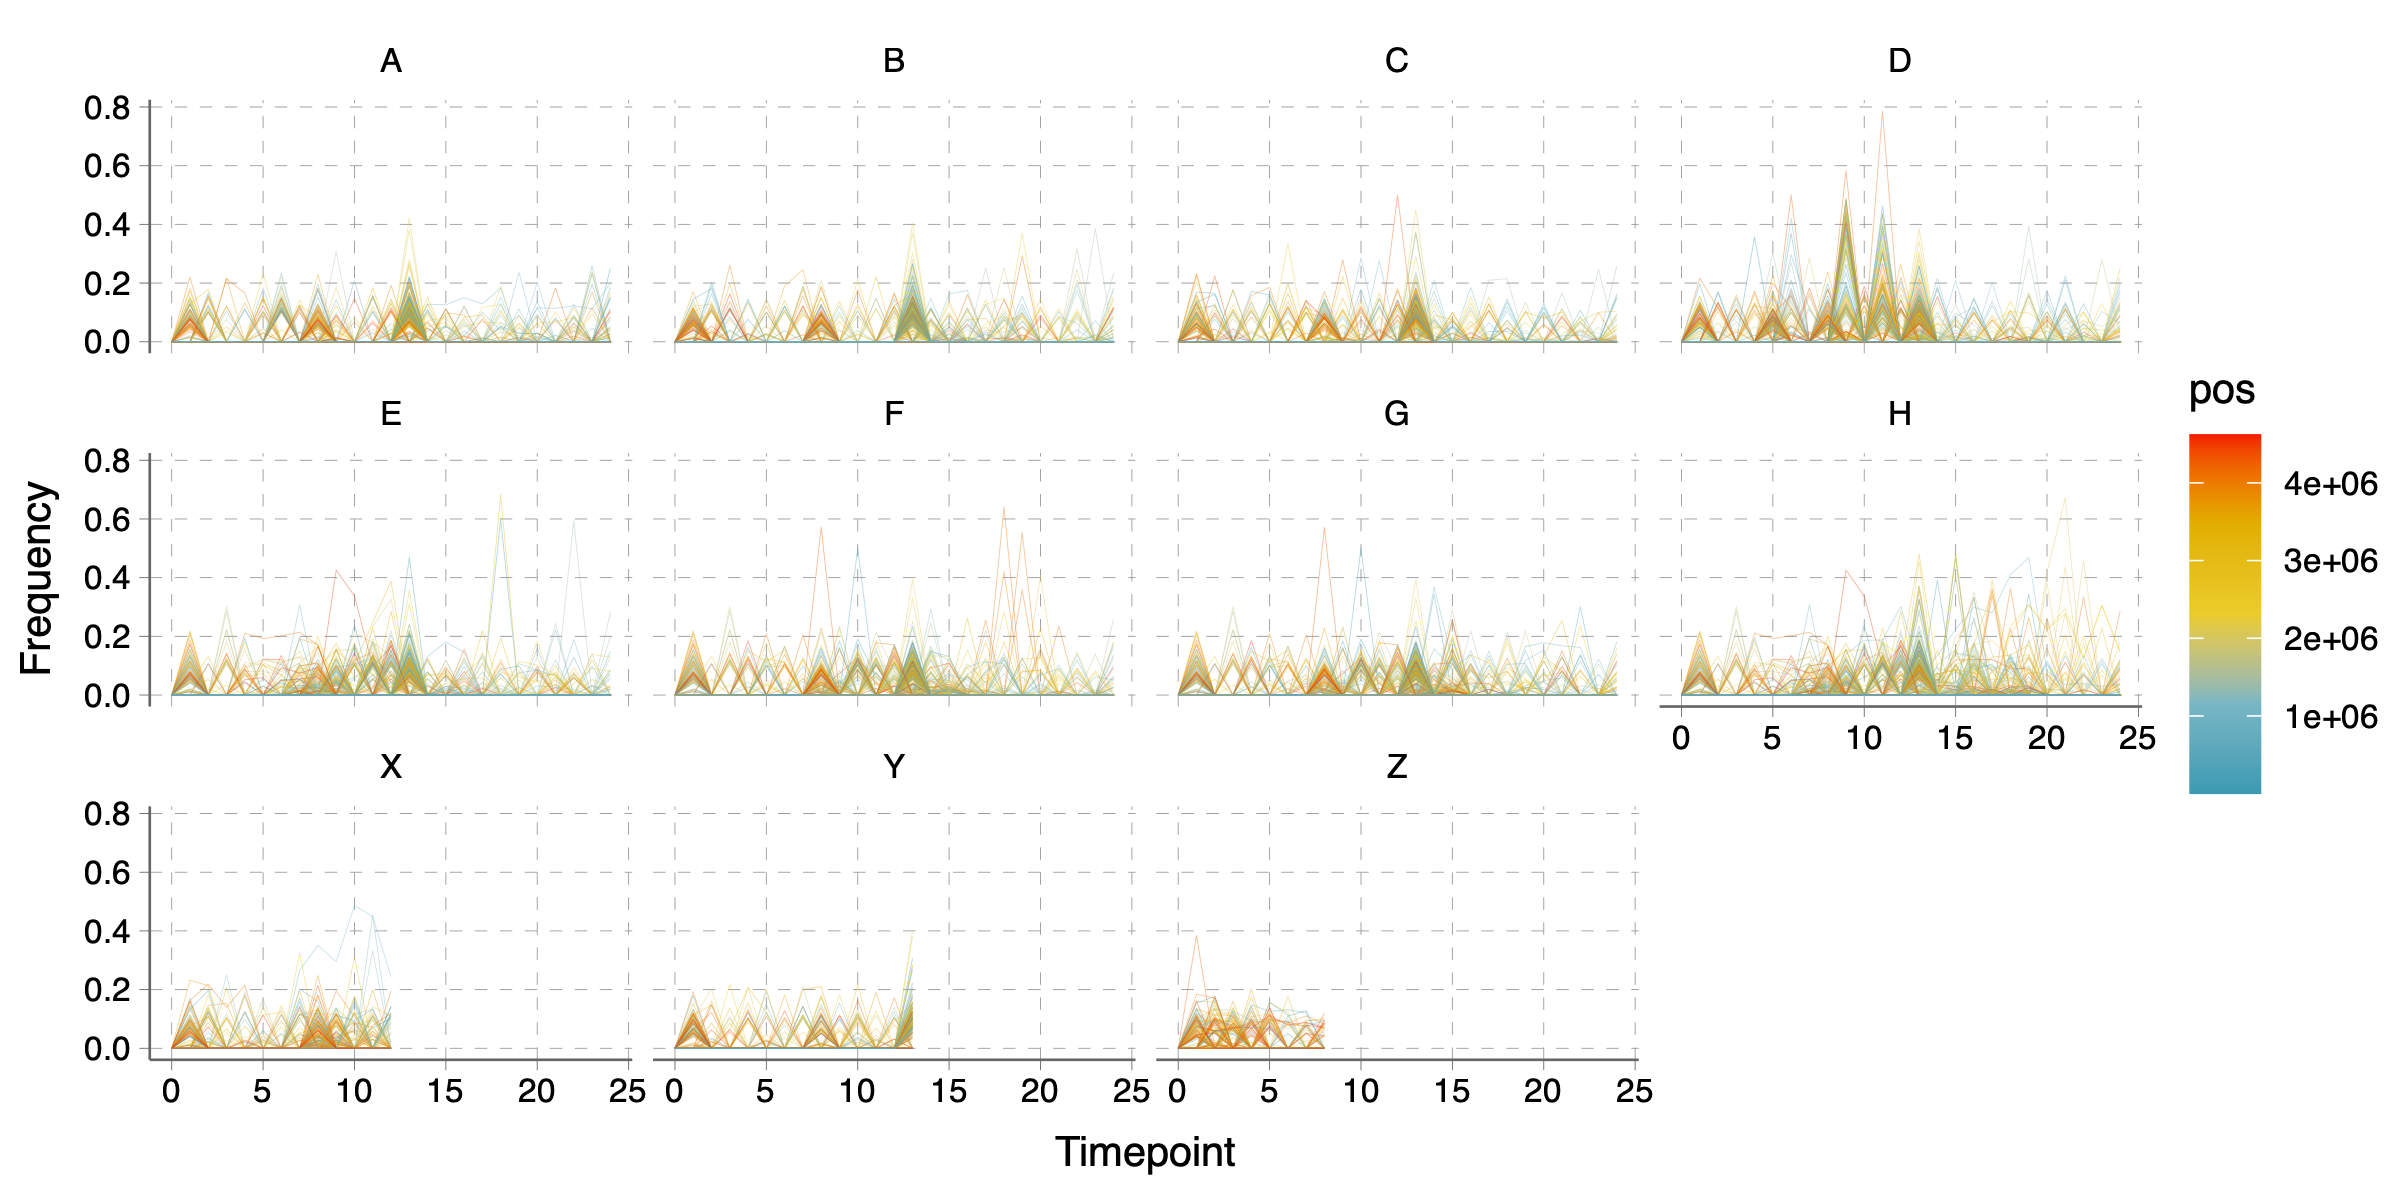

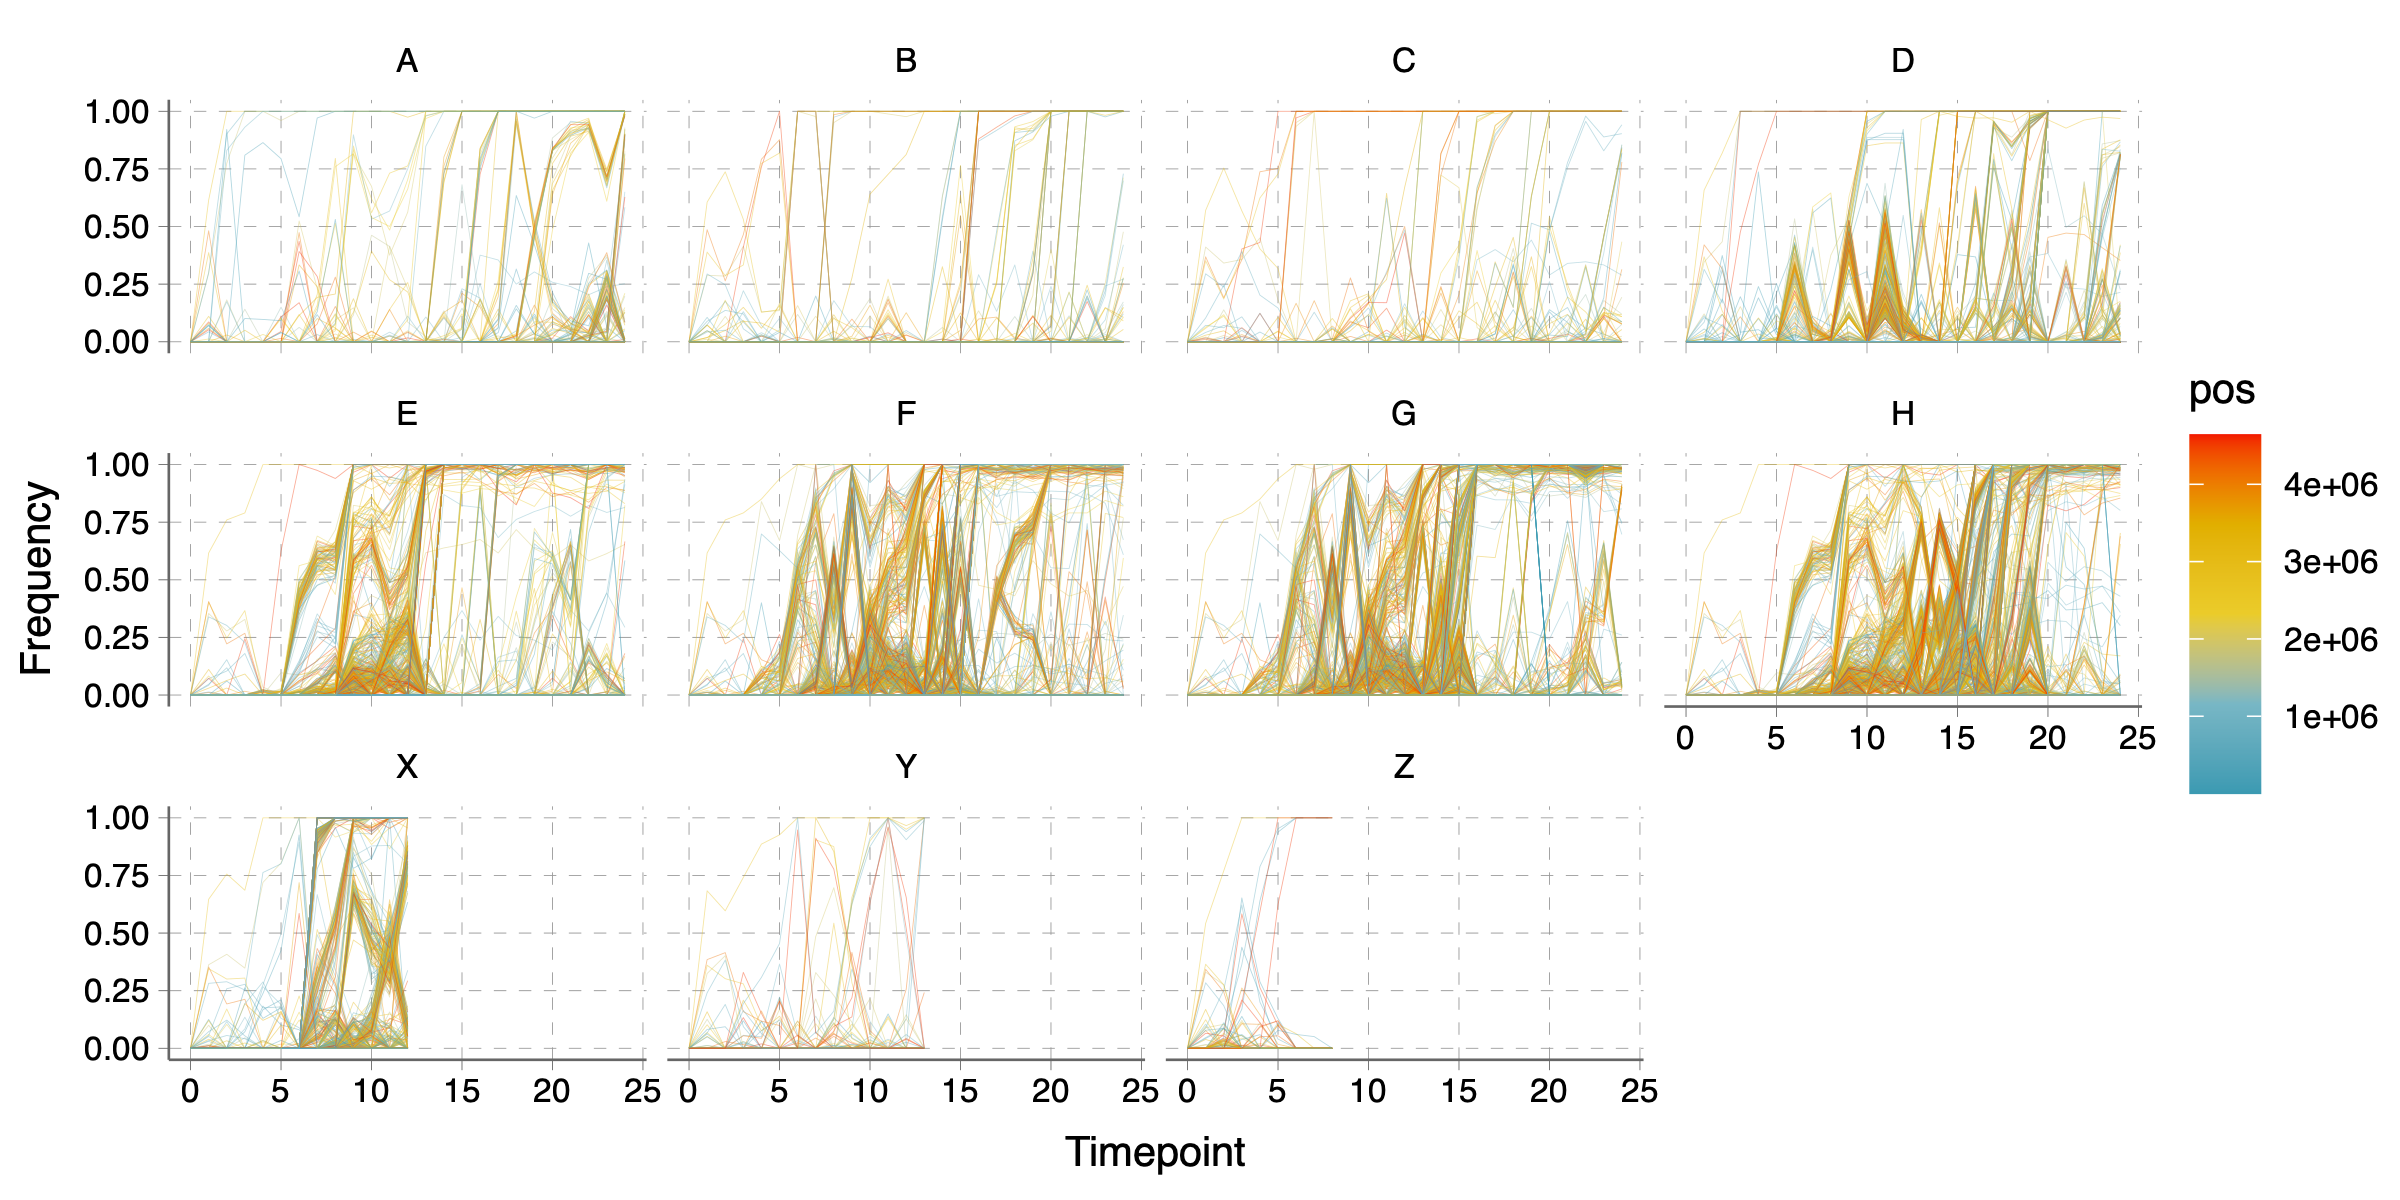

In [3]:
allele_thr = 4
cov_thr = 30
max_singletons = 5

d_coarse = d %>%

    # Add a variant identifier
    mutate(v_string = paste(chrom, pos, ref, alt, origin, sep = '_')) %>% 

    # Add maximum reached frequency
    group_by(pop, v_string) %>%
    mutate(max_f_variant = max(freq)) %>% 

    arrange(pop, chrom, pos, ref, alt, wave, gen) %>%

    # Within-lineage characteristics
    group_by(pop, chrom, pos, ref, alt, wave) %>%
    mutate(
        singleton = freq > 0 & lag(freq, default = 0) == 0 & lead(freq, default = 1) == 0 & pop == origin,
        present = freq > 0 & pop == origin,
        already_there = lag(freq, default = 0) > 0 & pop == origin
        ) %>%

    # Unique variant characteristics
    group_by(chrom, pos, ref, alt) %>%
    mutate(
        autocor = ifelse(sum(present) > 1, cor(present, already_there), 1),
        n_singleton = sum(singleton),
        gen_13_bg = any(name == 'EB13' & freq > 0 & freq < 0.5),
        enough_evidence = any(allele_depth > allele_thr & total_depth > cov_thr),
        bg = !(max_f_variant > 0.5 | (n_singleton < max_singletons & autocor > 0))
        ) %>%
    ungroup()

# Show what we are removing
size(4, 8)
d_coarse %>% filter(gen_13_bg | bg | !enough_evidence, nchar(pop) == 1) %>% fp()

# Remove it
d_coarse = d_coarse %>%
    filter(!bg, !gen_13_bg, enough_evidence) %>%
    select(-c(present, already_there, gen_13_bg, bg, singleton, n_singleton, enough_evidence))

#d_coarse[d_coarse$gen == 0, 'coverage'] = Inf # for later convenience

# Show what keep
d_coarse %>% filter(nchar(pop) == 1) %>% fp()

# Handle reversions

* **Masked variants:**
If there is a deletion around a fixed variant, it will look like the variant reverted. However, its coverage will go down to zero.
This is notably the case at timepoint 24 in E and H, for a total of 7 variants around 29000. These can be corrected using the `endpoint_coverages` file from the previous notebook.

* **Overwritten variants:** when a new variant appears on top of a previous variant.

* **One-point fixations:** when a variant reaches 1 for only one timepoint, and is less than 100% of the reads, it means it was rounded up to 1 by Breseq by mistake.

* **Flash reversions in stretches:** in long stretches (>5bp) a fixed mutation will completely disappear and reappear, often with a different repeat number (`delta`). For continuity, fill up the gap and set the repeat number to 0 for that generation. (Example: if a stretch of 8 A's becomes a stretch of 9 A's, then 8 again, then 7, it will look like two mutations: one before the "reversion" and a second one after. Instead, I'd like to track all of that as "the same" variant. Otherwise, this may look like a super important locus that keeps getting mutations, while in fact it's merely a boring nucleotide repeat stretch.)

## Masked variants
Some mutations are masked by a future deletion that encompasses the locus. Use the endpoint coverage to find such alleles.

Joining with `by = join_by(pop, chrom, pos)`


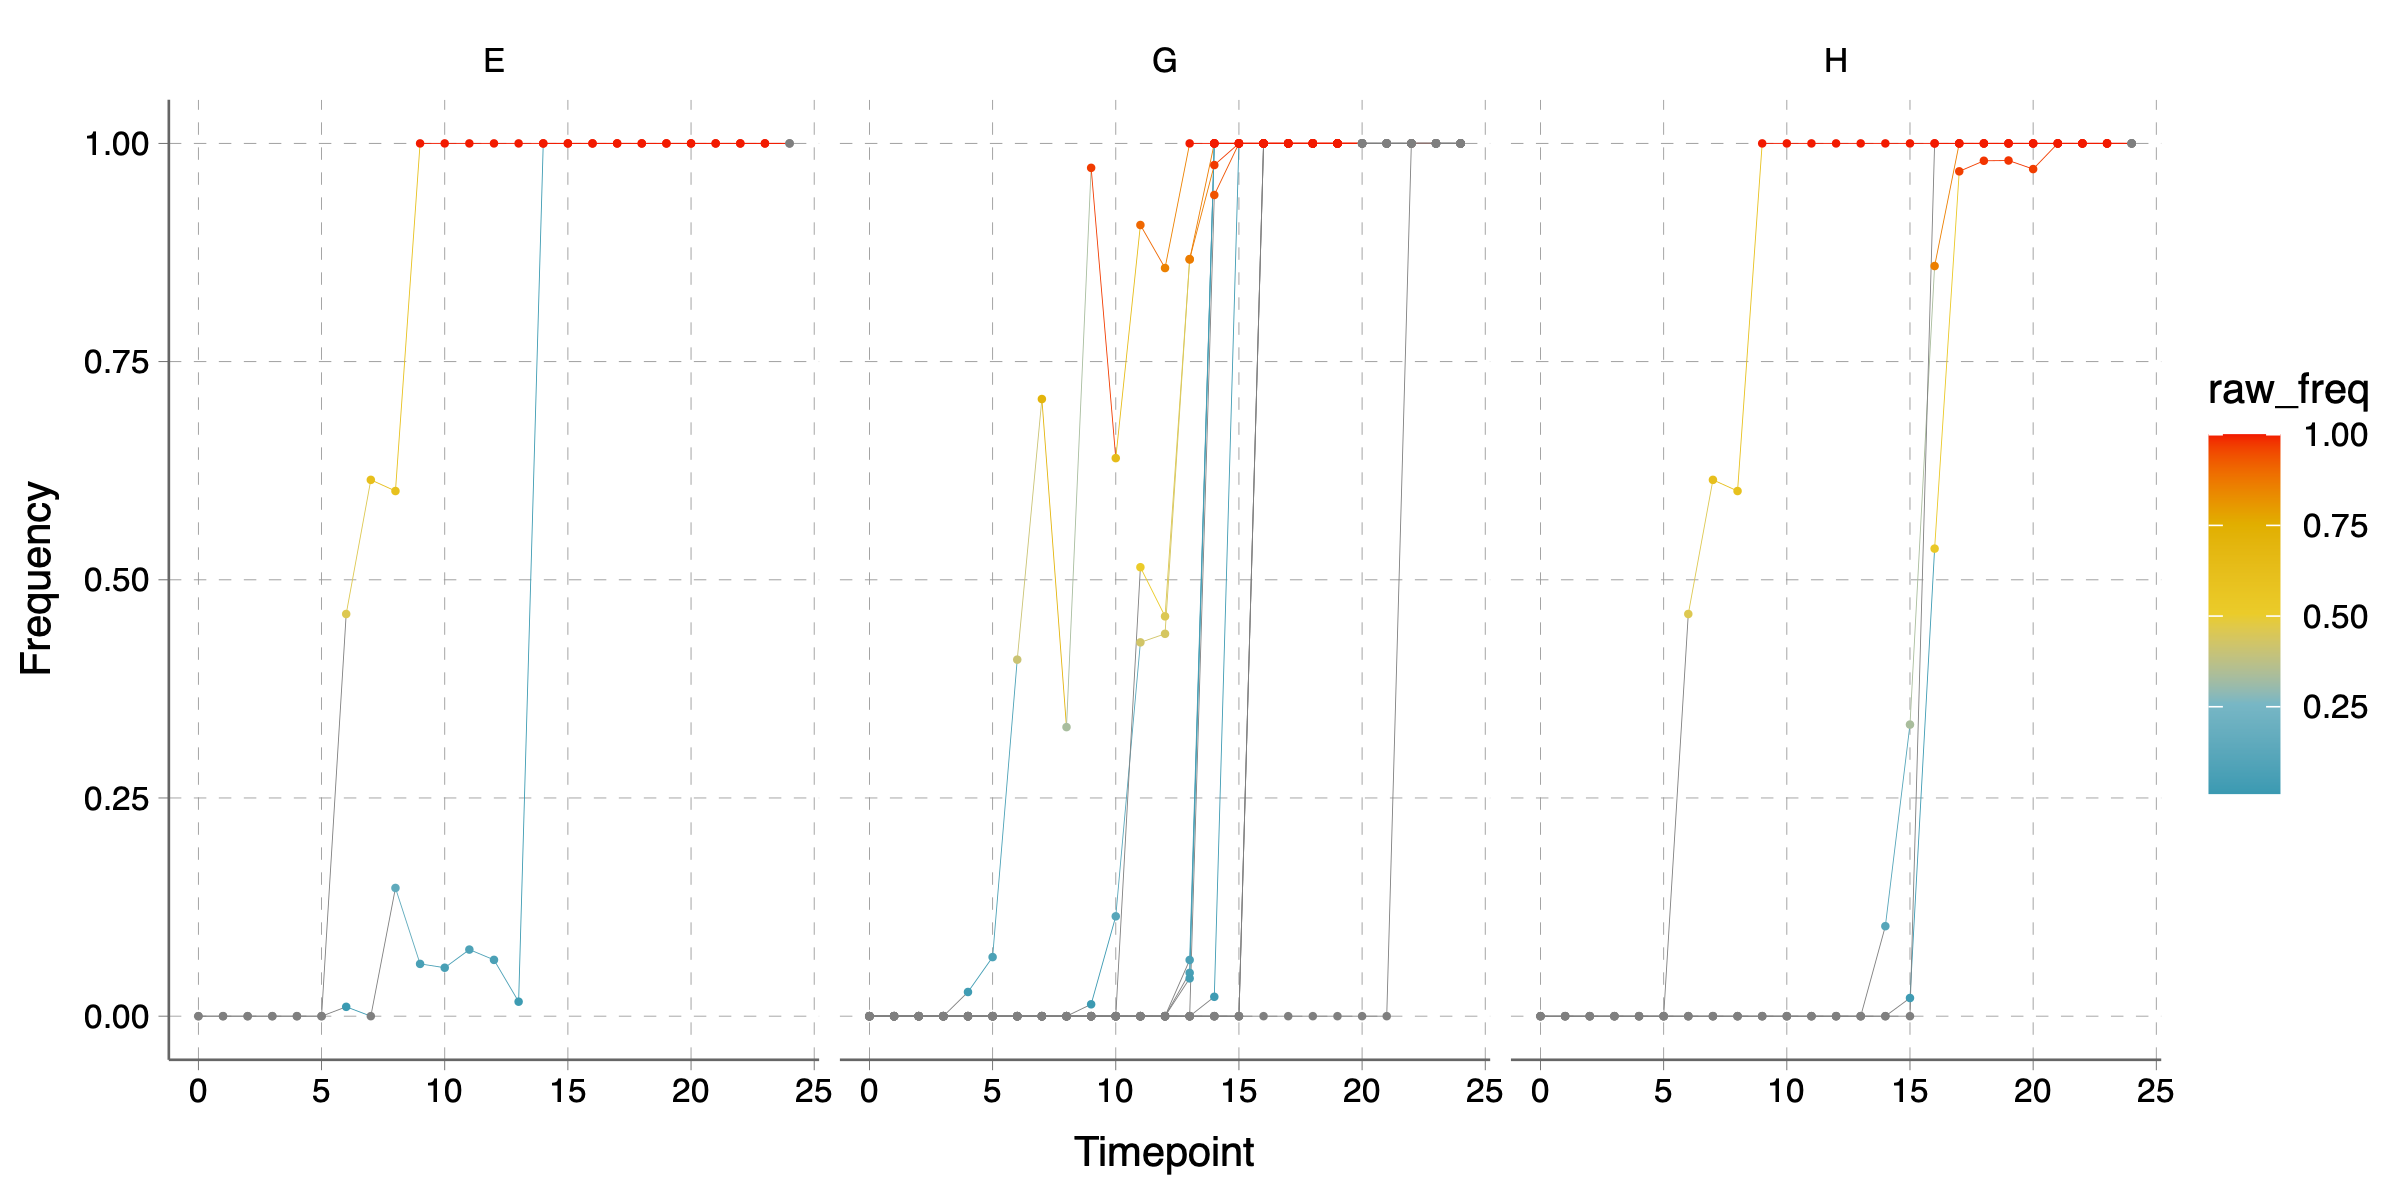

In [4]:
fix_thr = 1

endpoint_coverages = 
    read.tsv('../../../datasets/genomics/03_variant_filtering/intermediate/endpoint_coverages.tsv') %>% 
    mutate(masked = endpoint_cov == 0) %>% select(pop, chrom, pos, masked)

d_no_masked =
d_coarse %>% 

    # Keep track of edits
    mutate(edits = 'None') %>% 

    left_join(endpoint_coverages) %>% replace_na(masked, FALSE) %>% 

    # Identify reversion events
    group_by(pop, chrom, pos, ref, alt, wave) %>%
    mutate(
        rev = lag(freq, default = 0) >= fix_thr & freq < fix_thr,
        rev_gen = min(gen[rev], Inf),
        reverted = gen >= rev_gen,
        freq = if_else(reverted & masked, 1, freq),
        edits = if_else(reverted & masked, 'Masked', edits),
        reverted = if_else(reverted & masked, FALSE, reverted)
    )

d_no_masked %>%  
    filter(
        any(edits == 'Masked')
        ) %>% 

    freqplot() + aes(col = raw_freq)

## Overwritten variants
On rare occasions some alleles were overwritten by another mutation, leading to an apparent reversion.
* 3024407 in G: T>C is overwritten by T>.
* 2883092 in G: T>. is overwritten by T>C
* 638787 in E: C>G is overwritten by C>.
* 3213852 in D: T>G is overwritten by T>A

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


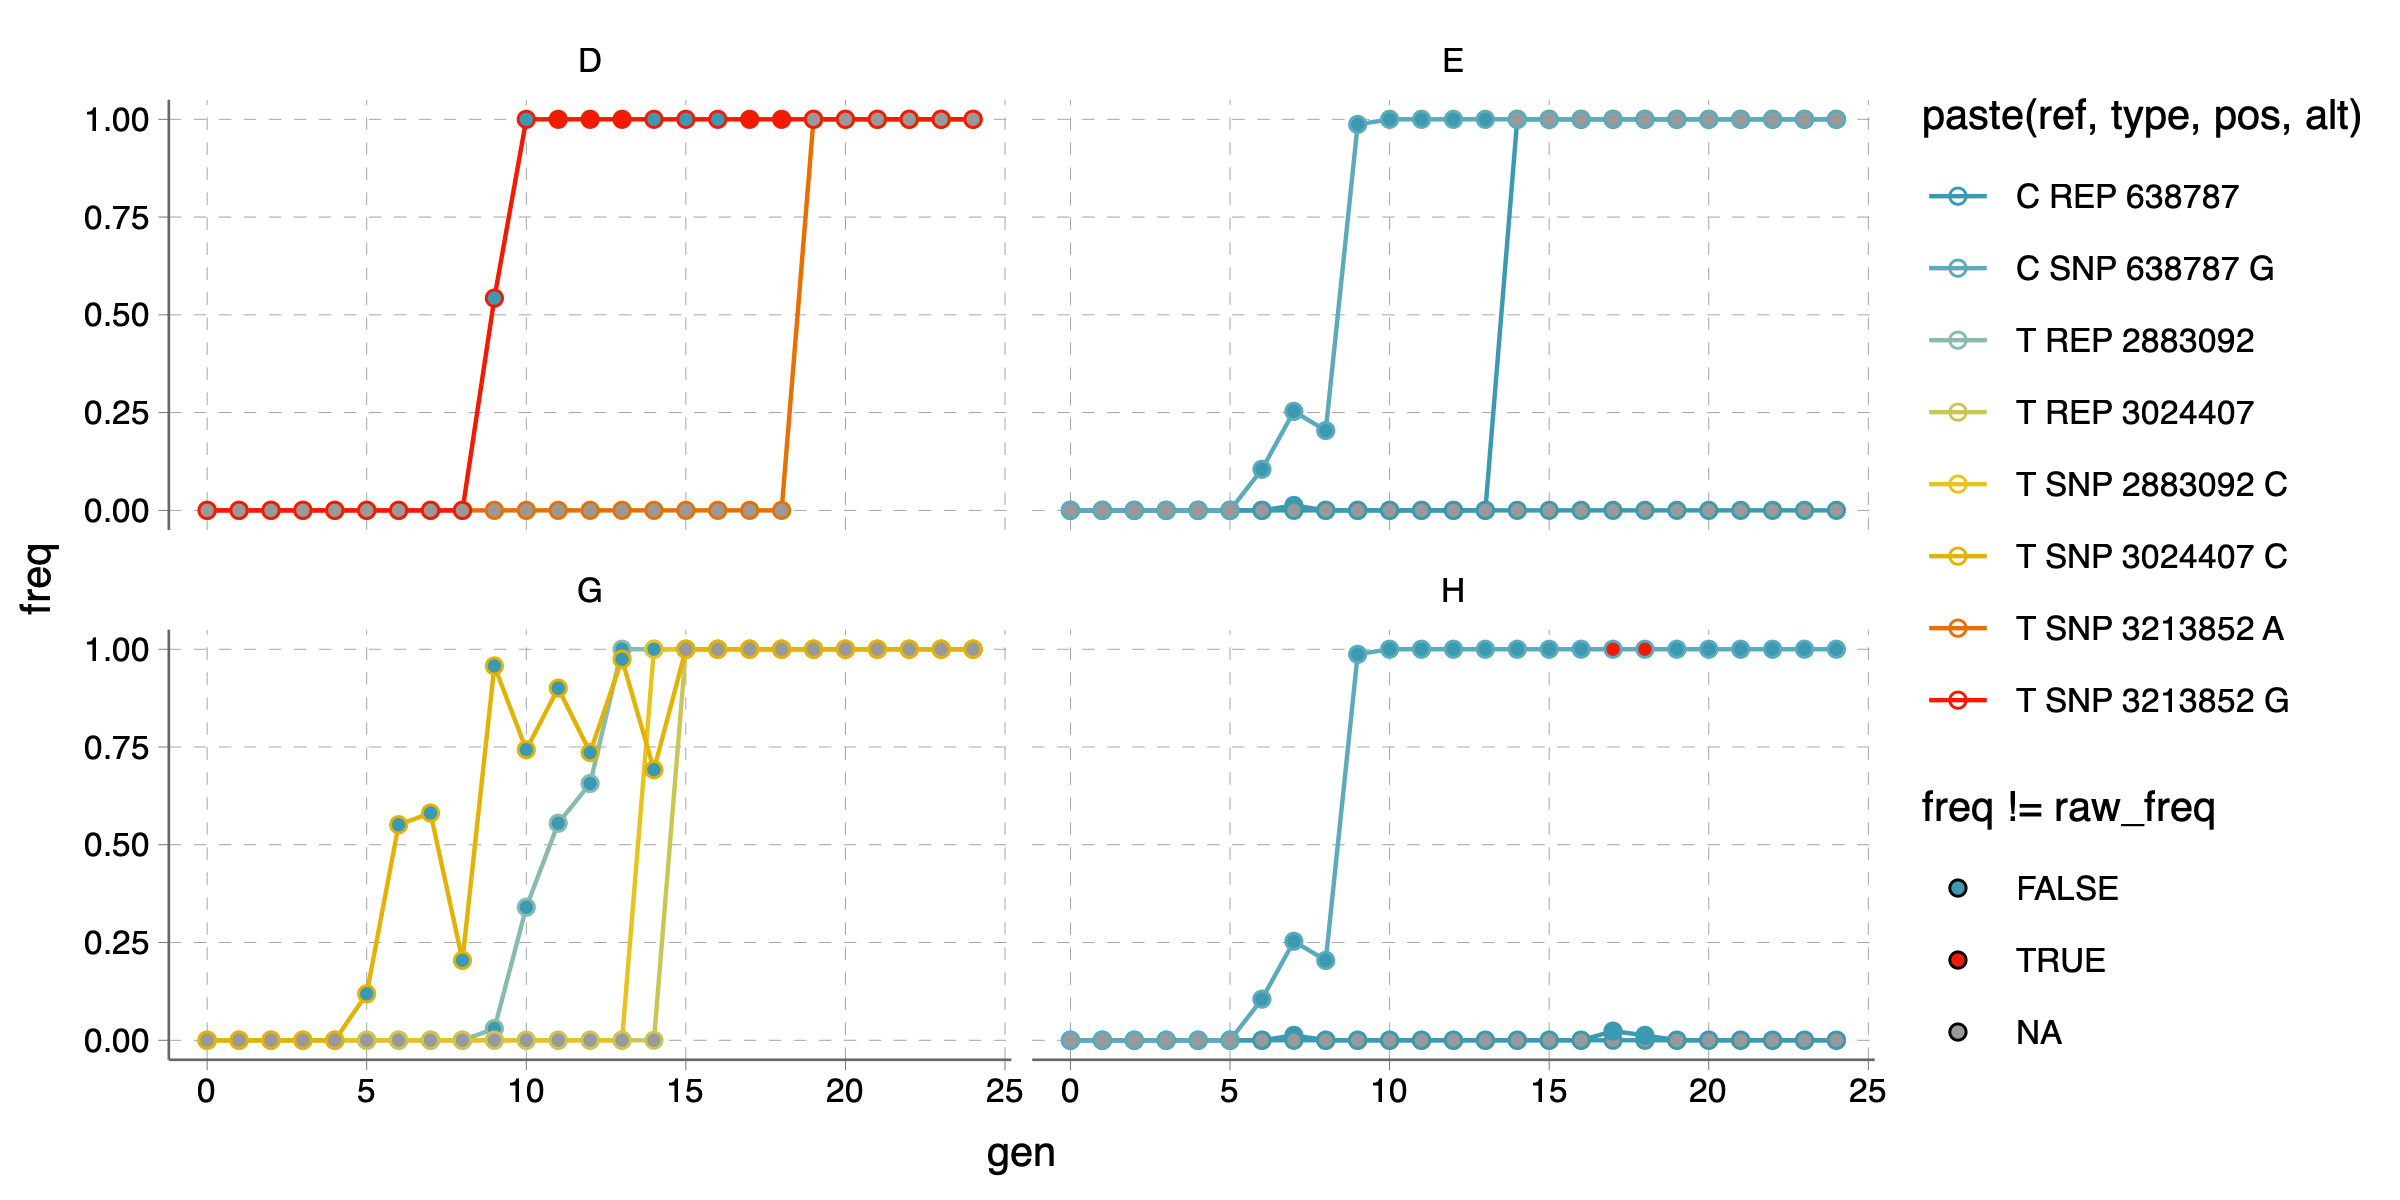

In [5]:
d_no_overwriting = d_no_masked %>%

    group_by(pop, gen, chrom, pos) %>%
    mutate(
        overwritten = n_distinct(alt) > 1 & reverted | (pop == 'G' & pos == 3024407 & alt == 'C' & gen >= 15), # very shaky mutation, overwriting is the only thing that makes sense
        freq = ifelse(overwritten, 1, freq),
        edits = ifelse(overwritten, 'Overwritten', edits)
    ) %>%
    ungroup()

d_no_overwriting %>% 
    group_by(pop, chrom, pos) %>% 
    filter(any(overwritten)) %>% 
    filter(nchar(pop) == 1) %>% 

ggplot() + 
    aes(x = gen, y = freq, col = paste(ref, type, pos, alt), fill = freq != raw_freq, group = paste(ref, type, pos, alt, wave)) +
    facet_wrap(~pop) +
    geom_line() + geom_point(pch = 21)

In [6]:
flash_fix_thr = 0.90 # arbitrary freq to assign to false fixations
min_stretch = 5

d_no_false_rev =

    d_no_overwriting %>% 

    # Flash fixation/reversion of long-stretch repeat (>=8bp) number changes
    group_by(pop, chrom, pos, ref, alt, wave) %>% 
    mutate(
        flash_fix = lag(freq, default = 0) == 0 & freq == 1 & lead(freq, default = 1) == 0 & type == 'REP',
        freq = ifelse(flash_fix, 0, freq),
        edits = ifelse(flash_fix, 'Flash_fixation', edits),
        
        flash_rev = lag(freq, default = 0) == 1 & freq < 1 & lead(freq, default = 1) == 1,
        freq = ifelse(flash_rev, 1, freq),
        edits = ifelse(flash_rev, 'Flash_reversion', edits),

        one_point_fix = lag(freq, default = 0) < flash_fix_thr & freq == 1 & lead(freq, default = 1) < flash_fix_thr,
        freq = ifelse(one_point_fix, flash_fix_thr, freq),
        edits = ifelse(one_point_fix, 'One_point_fixation', edits)
        ) %>%

    ungroup() %>%
    select(-c('rev', 'rev_gen', 'overwritten', 'flash_fix', 'flash_rev', 'one_point_fix', 'max_f_variant', 'autocor'))

# Find the true reversions
At this point apparent reversions are either:
* True reversions: mutS in EFGH, plus 2 in E, 1 if F and 2 in G. All go to zero at gen 24, except 431974 in G that goes to 0.097
* The mutS variant in H possibly reverted *twice*, coming back in the middle due to genetic hitchhiking
* False unfixation events in fixed variants (very common in long REPs). Some stay at a frequency around 0.9 the entire time, even though other variants reach fixation during the same period.
* Whatever happened at the beginning on B (left unchanged)

**Policy**
* Split the variant in two: the original and the reversion event
* Once reversed, the original's frequency is kept at 1
* The reversion event's frequency is set to 1 - (original's freq while reverting)

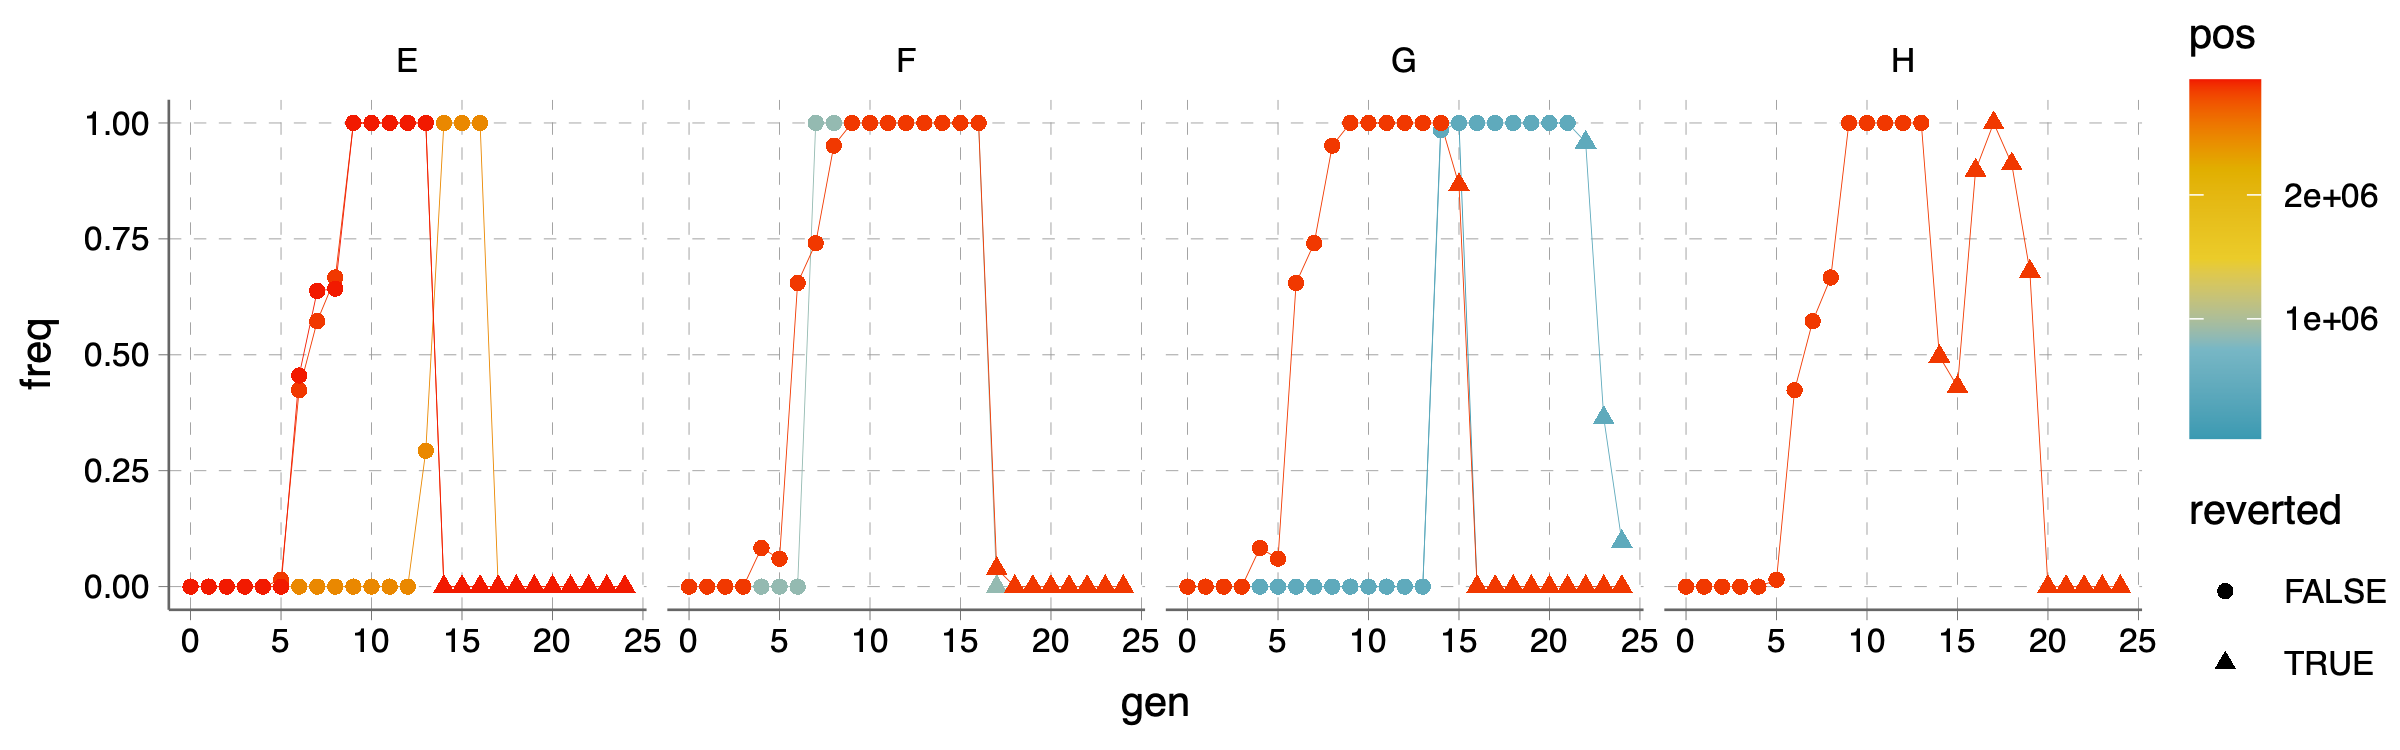

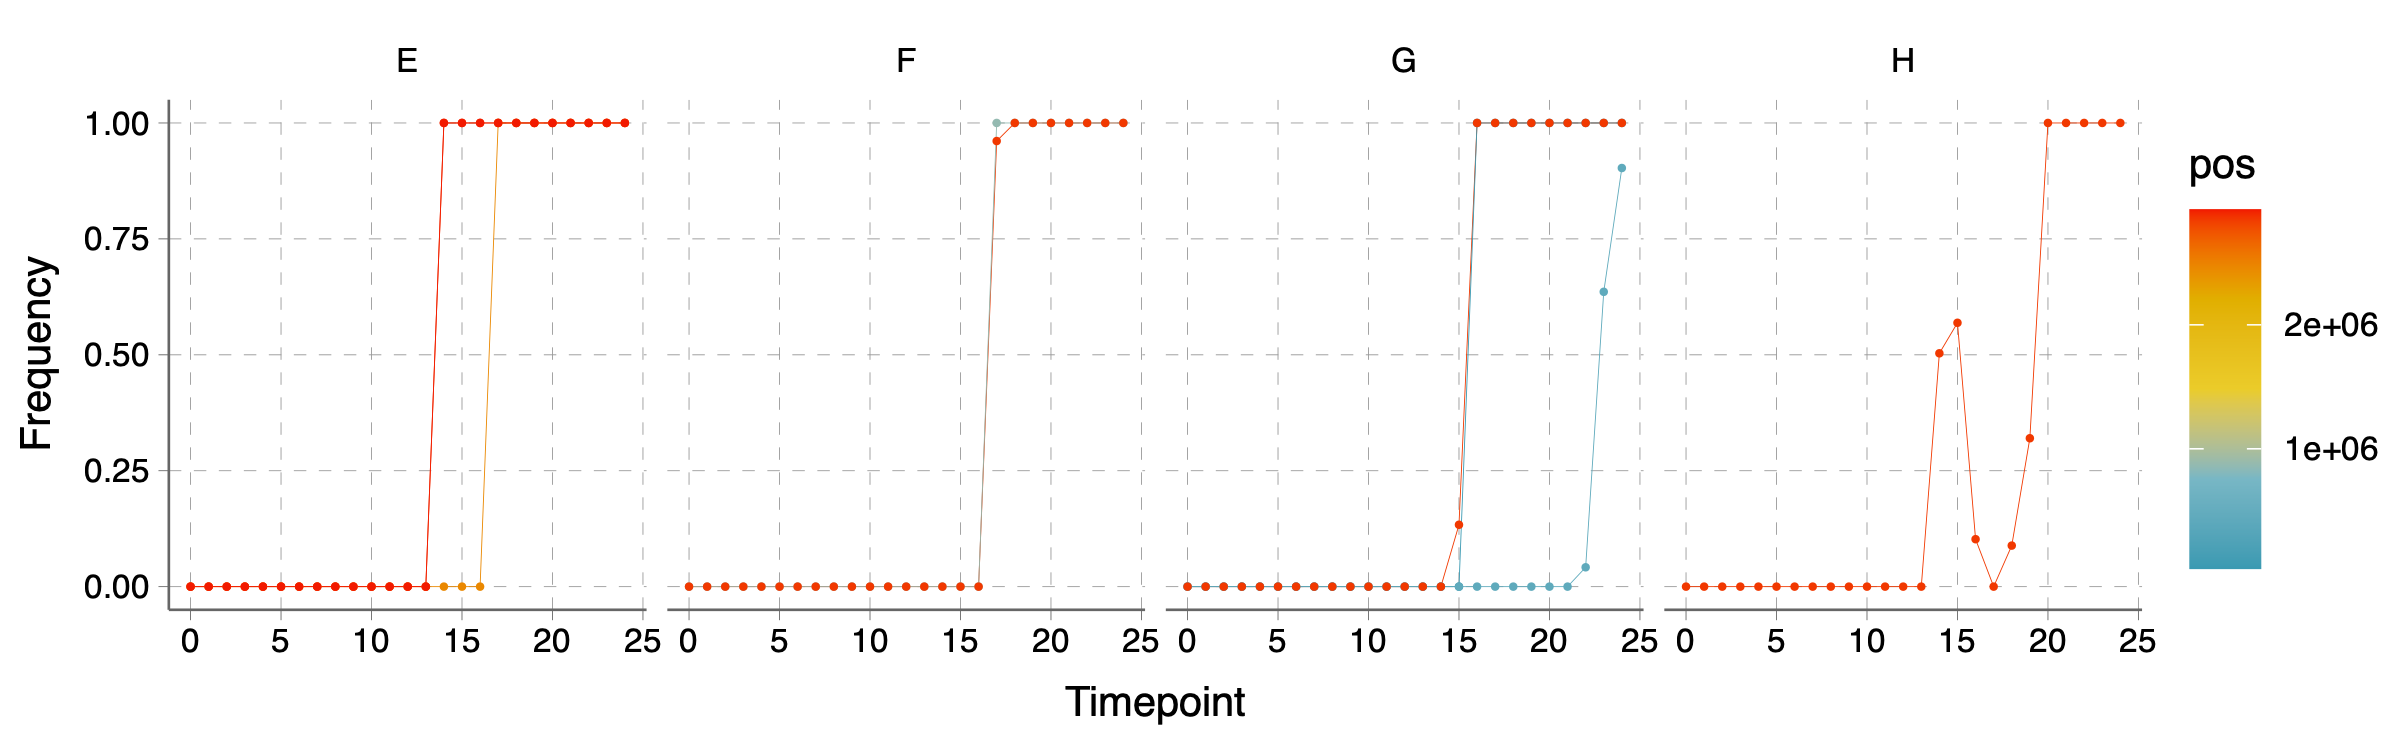

In [7]:
short()

extinction_thr = 0.1

d_no_rev =
d_no_false_rev %>%
    group_by(pop, chrom, pos, ref, alt, wave) %>% 
    mutate(
        # Find the reverted generations
        rev = lag(freq, default = 0) >= 1 & freq < 1,
        genrev = ifelse(any(rev), min(gen[rev]), max(gen) + 1),
        
        # Select only the true reversions
        reverted = (gen >= genrev) & (freq[gen == max(gen)] <= extinction_thr) & pop != 'B'
    ) %>%
    select(-c(rev, genrev)) # Keep grouped

# Show the reversions
d_no_rev %>%
    filter(any(reverted)) %>% 
ggplot() + aes(x = gen, y = freq, col = pos, group = pos, shape = reverted) + facet_wrap(~pop, ncol = 4) + geom_line(linewidth = 0.1) + geom_point()

# Make the prosthetics
prosthesis = d_no_rev %>%
    filter(any(reverted)) %>% 
    mutate(
        freq = 1 - ifelse(reverted, freq, 1),
        ref = '', alt = '', delta = 0, type = 'REV', edits = 'Reversion'
    )

prosthesis %>% freqplot()

d_no_rev =
d_no_rev %>%
    # Set reverted variants to 1
    mutate(
        freq = ifelse(reverted, 1, freq),
        edits = ifelse(reverted, 'Reverted', edits)
    ) %>% 
    
    # Add the reversion variants
    rbind(prosthesis) %>%
    ungroup() %>% 
    select(-reverted)

# Detect selective sweeps
If a variant sweeps over the population (going from 0 to 100%), all the other variants that were at an intermediate frequency *before* the sweep should also go to 100% *after* the sweep.
If they don't, it's probably not a legit variant.

### Make a sweep dataset
First, detect all clear genetic sweeps:

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by pop, last_zero, first_one, sweep_id, and
  gen.
ℹ Output is grouped by pop, last_zero, first_one, and sweep_id.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(pop, last_zero, first_one, sweep_id, gen))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


[1] 4264

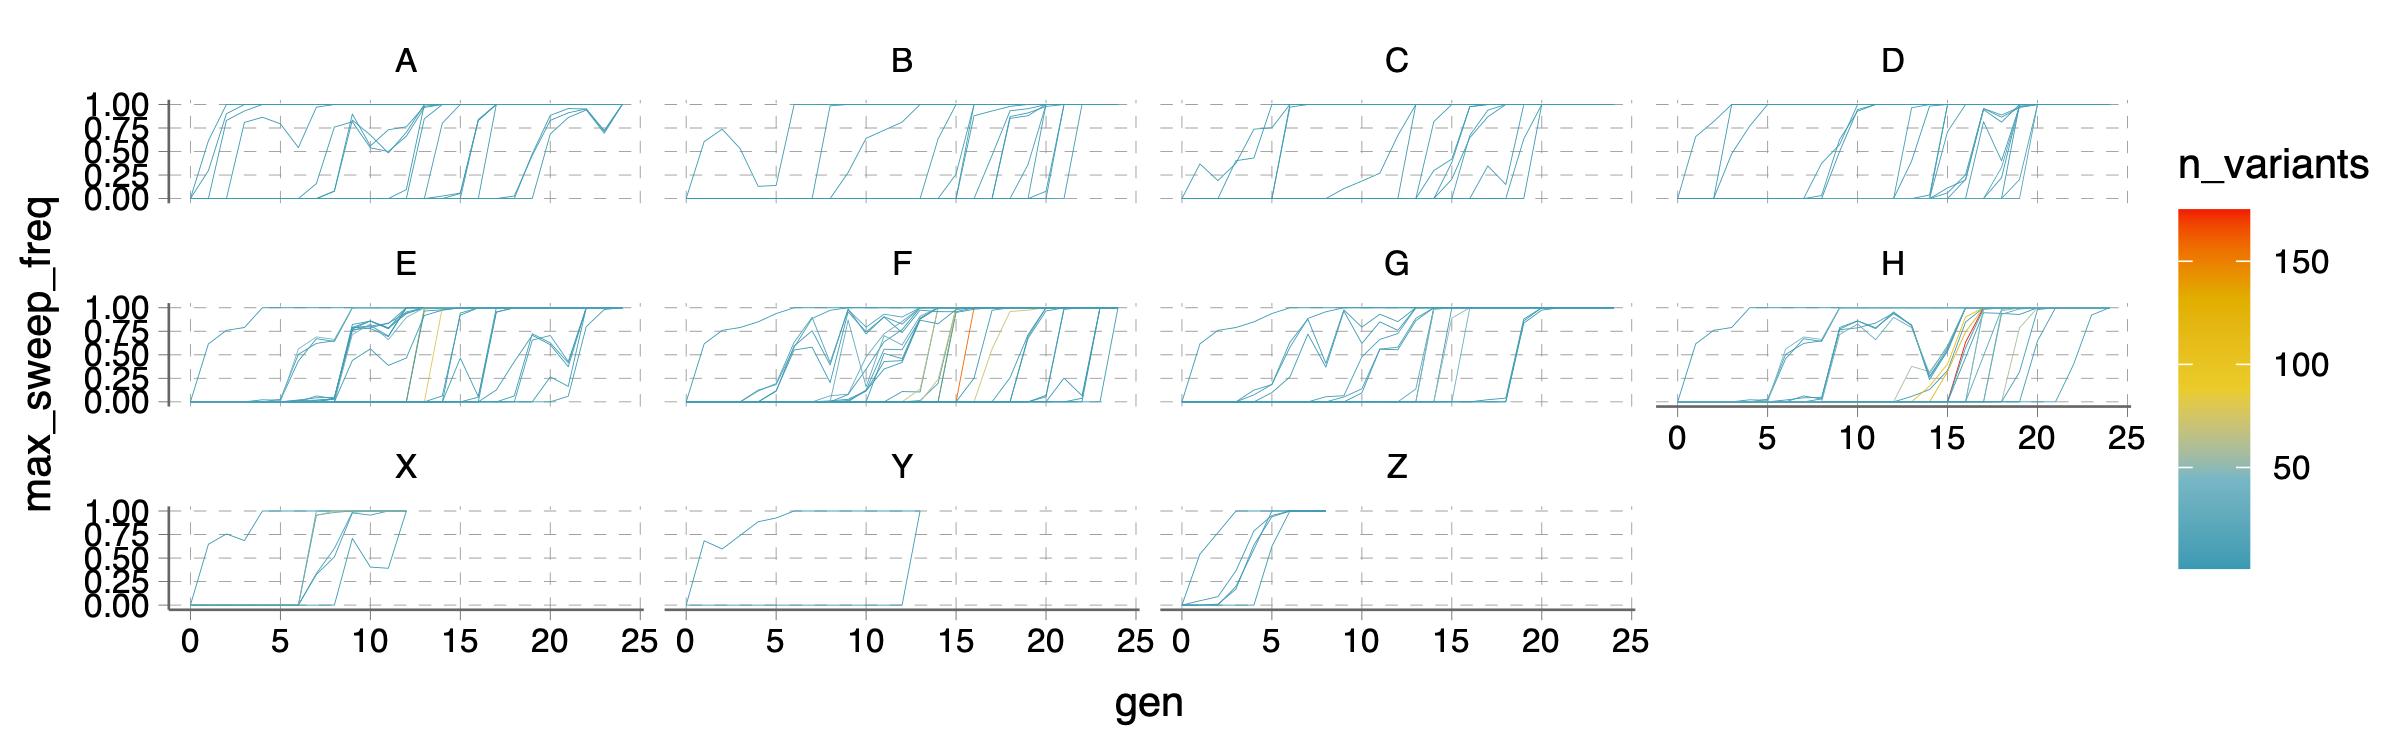

In [8]:
sweeps = d_no_rev %>%

    group_by(pop, chrom, pos, ref, alt, wave) %>%

    # Traces that go from zero to one
    filter(
        any(freq == 1),
        any(freq == 0),
        type != 'REP', # do not use REPs as they're less reliable and might have been fixed in the processing earlier
        all(edits == 'None'), # do not use frequencies that have been edited
        wave == 1
        ) %>% 

    mutate(
        last_zero = max(gen[freq == 0]),
        first_one = min(gen[freq == 1]),
        rev = gen >= first_one & freq < 1,
        
        all_zeros = !any(allele_depth != 0 & gen <= last_zero),
        all_ones = !any(freq < 1 & gen >= first_one),
        n_zeros = sum(freq == 0 & gen <= last_zero),
        n_ones = sum(freq == 1 & gen >= first_one)
        ) %>%

    filter(all_zeros, all_ones) %>%
    mutate(
        sweep_id = paste(pop, last_zero, first_one, sep = '_')
    ) %>% 

    group_by(pop, last_zero, first_one, sweep_id, gen) %>%
    summarise(
        min_sweep_freq = min(freq),
        max_sweep_freq = max(freq),
        
        n_variants = n_distinct(v_string),
        n_zeros = sum(n_zeros),
        n_ones = sum(n_ones)
        ) %>%

    ungroup()

nrow(sweeps)

sweeps %>% 
ggplot() + aes(x = gen, y = max_sweep_freq, group = sweep_id, col = n_variants) + 
    geom_line(linewidth = 0.1) +
    facet_wrap(~pop, ncol = 4)

### Find variants that survive sweeps
"crosses" variable:
* NA: no crossing for this variant
* Negative: variant is present before sweep 
* Positive: variant is present after the sweep at intermediate freq
* Zero: during the sweep

In [9]:
error_margin = 0.05
last_timepoint = 24

# Find variants that are >0 at last_zero and <1 at first_one for any sweep
detect_sweep_crossings = function(pops, gens, freqs) {
    
    sw = sweeps %>% 
    filter(pop == pops[1]) %>% 
    left_join(tibble(pop = pops, gen = gens, freq = freqs), by = c('pop', 'gen')) %>%

    group_by(sweep_id, last_zero, first_one) %>% 
    summarise(
        above = freq[gen == last_zero] > 0,
        below = freq[gen == first_one] < 1 & freq[gen == first_one] > error_margin,
        n_sweep = n_variants[1],
        .groups = 'drop'
        ) %>% 
    filter(above & below)
            
    if (nrow(sw) > 0) {
        total_n_sweep = sum(sw$n_sweep)
        min_last_zero = min(sw$last_zero)
        min_first_one = min(sw$first_one)

        return(
            paste(min_last_zero, min_first_one, total_n_sweep)
        )
    } else {
        return(paste(-1, last_timepoint + 1, 0))
    }
}

**Warning: this cell takes time to execute**

In [10]:
d_crossings = 
    d_no_rev %>%

    group_by(pop, chrom, pos, ref, alt, wave) %>%
    mutate(
        crossings = detect_sweep_crossings(pop, gen, freq),
        min_last_zero = as.integer(str_split_i(crossings, ' ', 1)),
        min_first_one = as.integer(str_split_i(crossings, ' ', 2)),
        n_sweep = as.integer(str_split_i(crossings, ' ', 3))
        ) %>% 
    ungroup() %>%
    mutate(
        crosses = case_when(
            gen <= min_last_zero ~ -1,
            gen >= min_first_one ~ 1,
            n_sweep > 0 ~ 0,
            TRUE ~ NA
            )
        ) %>% 
    select(-crossings)

In [11]:
d_crossings %>% write.tsv('../../../datasets/genomics/03_variant_filtering/intermediate/d_crossings.tsv')

### Remove (low-frequency) crossers

There is a background of variants that are often present and cross genetic sweeps. Two types:
* Variants that stay at a low frequency (<0.75)
* Variants that may reach a high frequency, but never fix, go extinct by gen24, and are in long nucleotide repeats

They appear in different patterns depending on the sequencing service (HMS's for gen<=12, SeqCenter for gen>12 and 9), which makes it particularly tricky to remove them.

In [12]:
d_crossings = read.tsv('../../../datasets/genomics/03_variant_filtering/intermediate/d_crossings.tsv')

Warning message in geom_line(data = filter(sweeps, pop %in% popu), aes(y = max_sweep_freq, :
“Ignoring unknown aesthetics: shape”


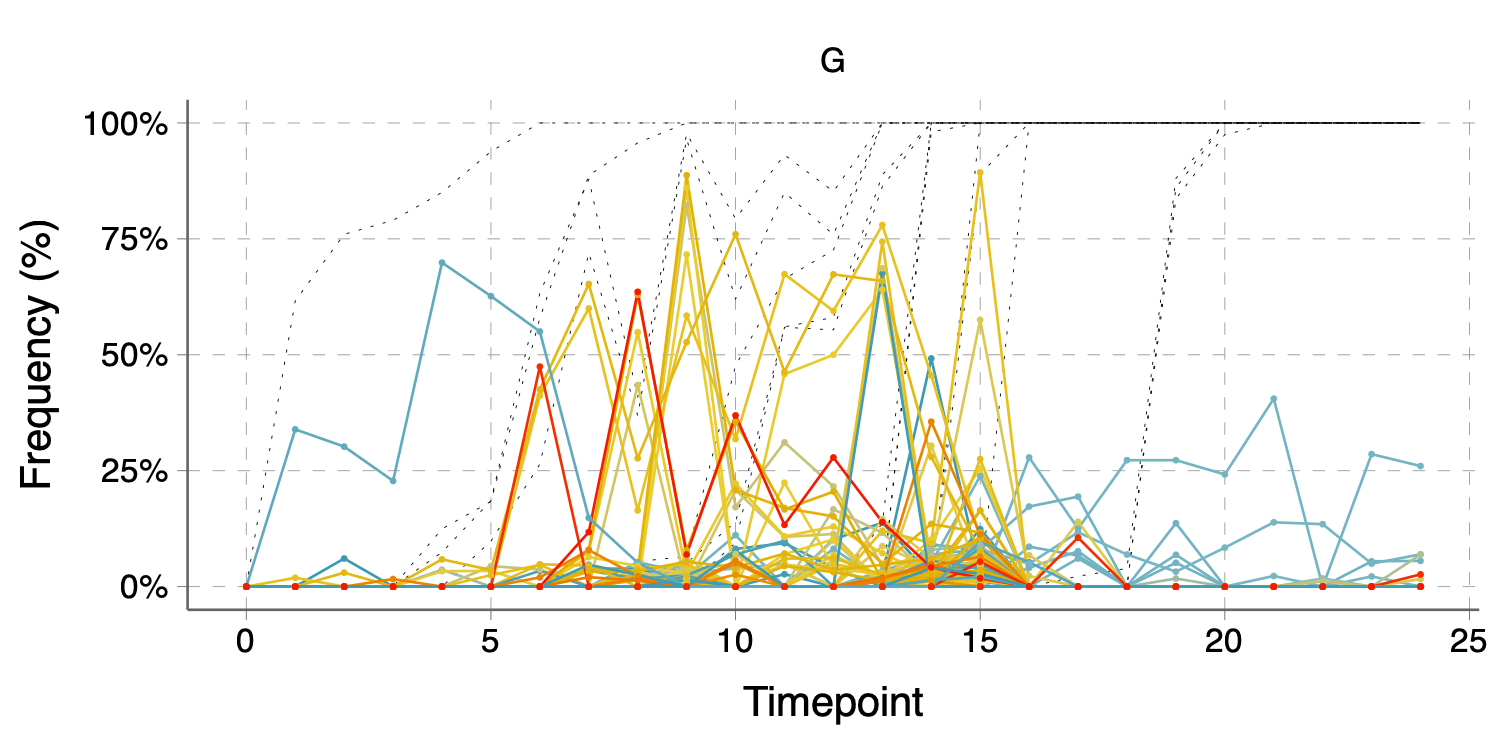

In [13]:
#big()
size(2.5, 5)

freq_thr = 0.75

popu = c('G')
#popu = c('A','B','C','D','E','F','G','H')

d_no_crossers =
d_crossings %>%

    group_by(pop, chrom, pos, ref, alt, wave) %>% 
    mutate(
        max_f_trace = max(freq),
        crosser = any(!is.na(crosses) & max(freq) < freq_thr)
    ) %>%

    group_by(chrom, pos, ref, alt) %>% 
    mutate(
        to_remove = any(crosser) & max_f_trace < freq_thr
    ) %>%

    group_by(pop, chrom, pos, ref, alt, wave) %>% 
    mutate(
        final_freq = freq[gen == max(gen)],
        to_remove = ifelse(any(!is.na(crosses)) & final_freq == 0, T, to_remove)
        ) %>% 
    ungroup()

# Show what we remove
d_no_crossers %>% 
    filter(
        pop %in% popu,
        to_remove
    ) %>%

ggplot() + aes(gen, freq,
               col = pos,
               group = paste(v_string, wave)) +

    # Sweeps
    geom_line(data = filter(sweeps, pop %in% popu), aes(y = max_sweep_freq, group = sweep_id, shape = TRUE), col = 'black', linewidth = 0.1, lty = 3) +

    # Crossers
    geom_line(linewidth = 0.3) + geom_point(size = 0.1) +
    scale_y_continuous(label = percent) +
    facet_wrap(~pop, ncol = 5) + nl +
    labs(x = 'Timepoint', y = 'Frequency (%)')

# Remove it
d_no_crossers =
    d_no_crossers %>%
    filter(!to_remove) %>%
    select(-crosser, -to_remove)

# Flatten pseudo-fixations
When variants stay around 100% forever, even as other variants reach fixation, it's probably an error.

Set them to 100% (mostly for aesthetics and clarity of plotting).

Warning message in geom_line(data = filter(sweeps, pop == popu), aes(y = max_sweep_freq, :
“Ignoring unknown aesthetics: shape”


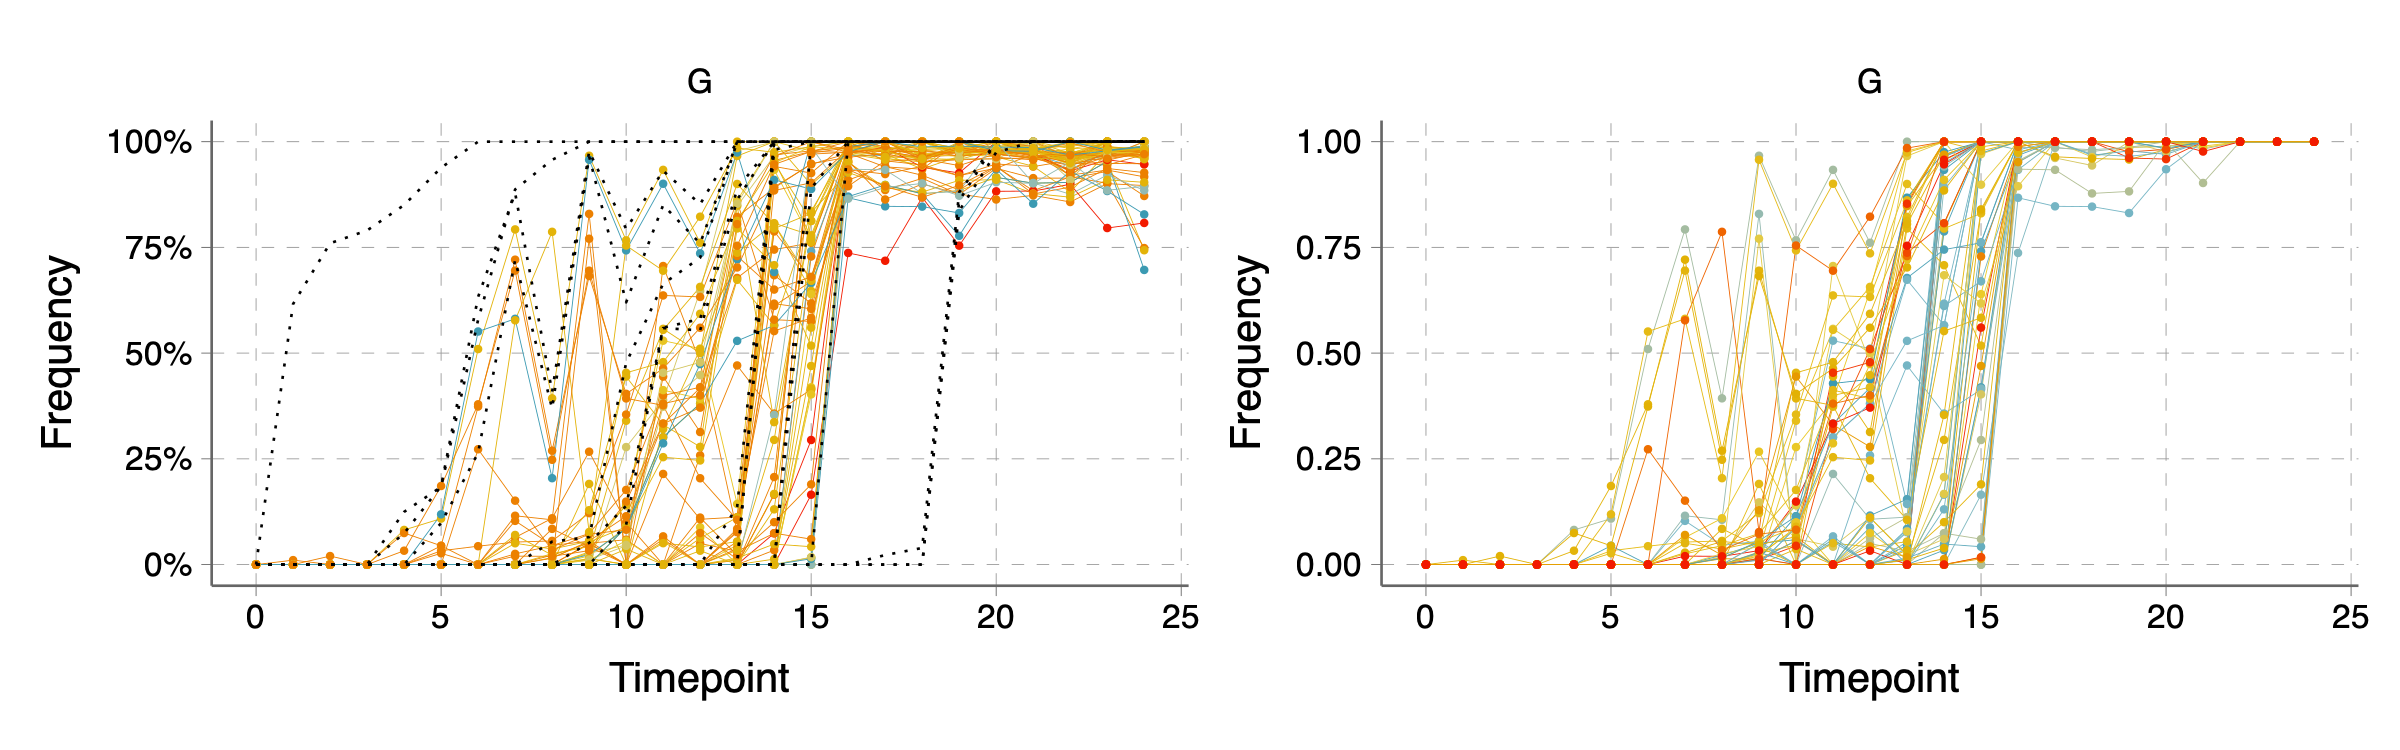

In [14]:
size(2.5, 8)

freq_thr = 0.5
max_freq_dist = 0.2

# Flatten the pseudo-fixations
freq_thr = 0.5
max_freq_dist = 0.2

# Flatten the pseudo-fixations
d_filtered =
d_no_crossers %>% 

    group_by(pop, chrom, pos, ref, alt, wave) %>% 
    mutate(
        pseudofixing = !is.na(crosses) & final_freq > freq_thr,
        first_pf = min(gen[pseudofixing & abs(freq - final_freq) < max_freq_dist & crosses == 1], max(gen) + 1),
        pseudofixed = gen > first_pf,
        freq = ifelse(pseudofixed, 1, freq)
        )

# Before / After plot
popu = 'G'

before_plot =
d_no_crossers %>% 

    group_by(pop, chrom, pos, ref, alt, wave) %>% 
    mutate(
        pseudofixing = !is.na(crosses) & final_freq > freq_thr,
        first_pf = min(gen[pseudofixing & abs(freq - final_freq) < max_freq_dist & crosses == 1], max(gen) + 1),
        pseudofixed = gen > first_pf,
        freq2 = ifelse(pseudofixed, 1, freq)
        ) %>% 
    filter(any(freq2 != freq), pop == popu) %>% 

freqplot() + nl + aes(col = rep_len) +    
    geom_line(data = filter(sweeps, pop == popu), aes(y = max_sweep_freq, group = sweep_id, shape = TRUE), col = 'black', linewidth = 0.3, lty = 3) +

    scale_y_continuous(label = percent)

after_plot =
d_filtered %>% 
    filter(any(pseudofixed), pop == popu) %>% 

freqplot() + nl

before_plot | after_plot

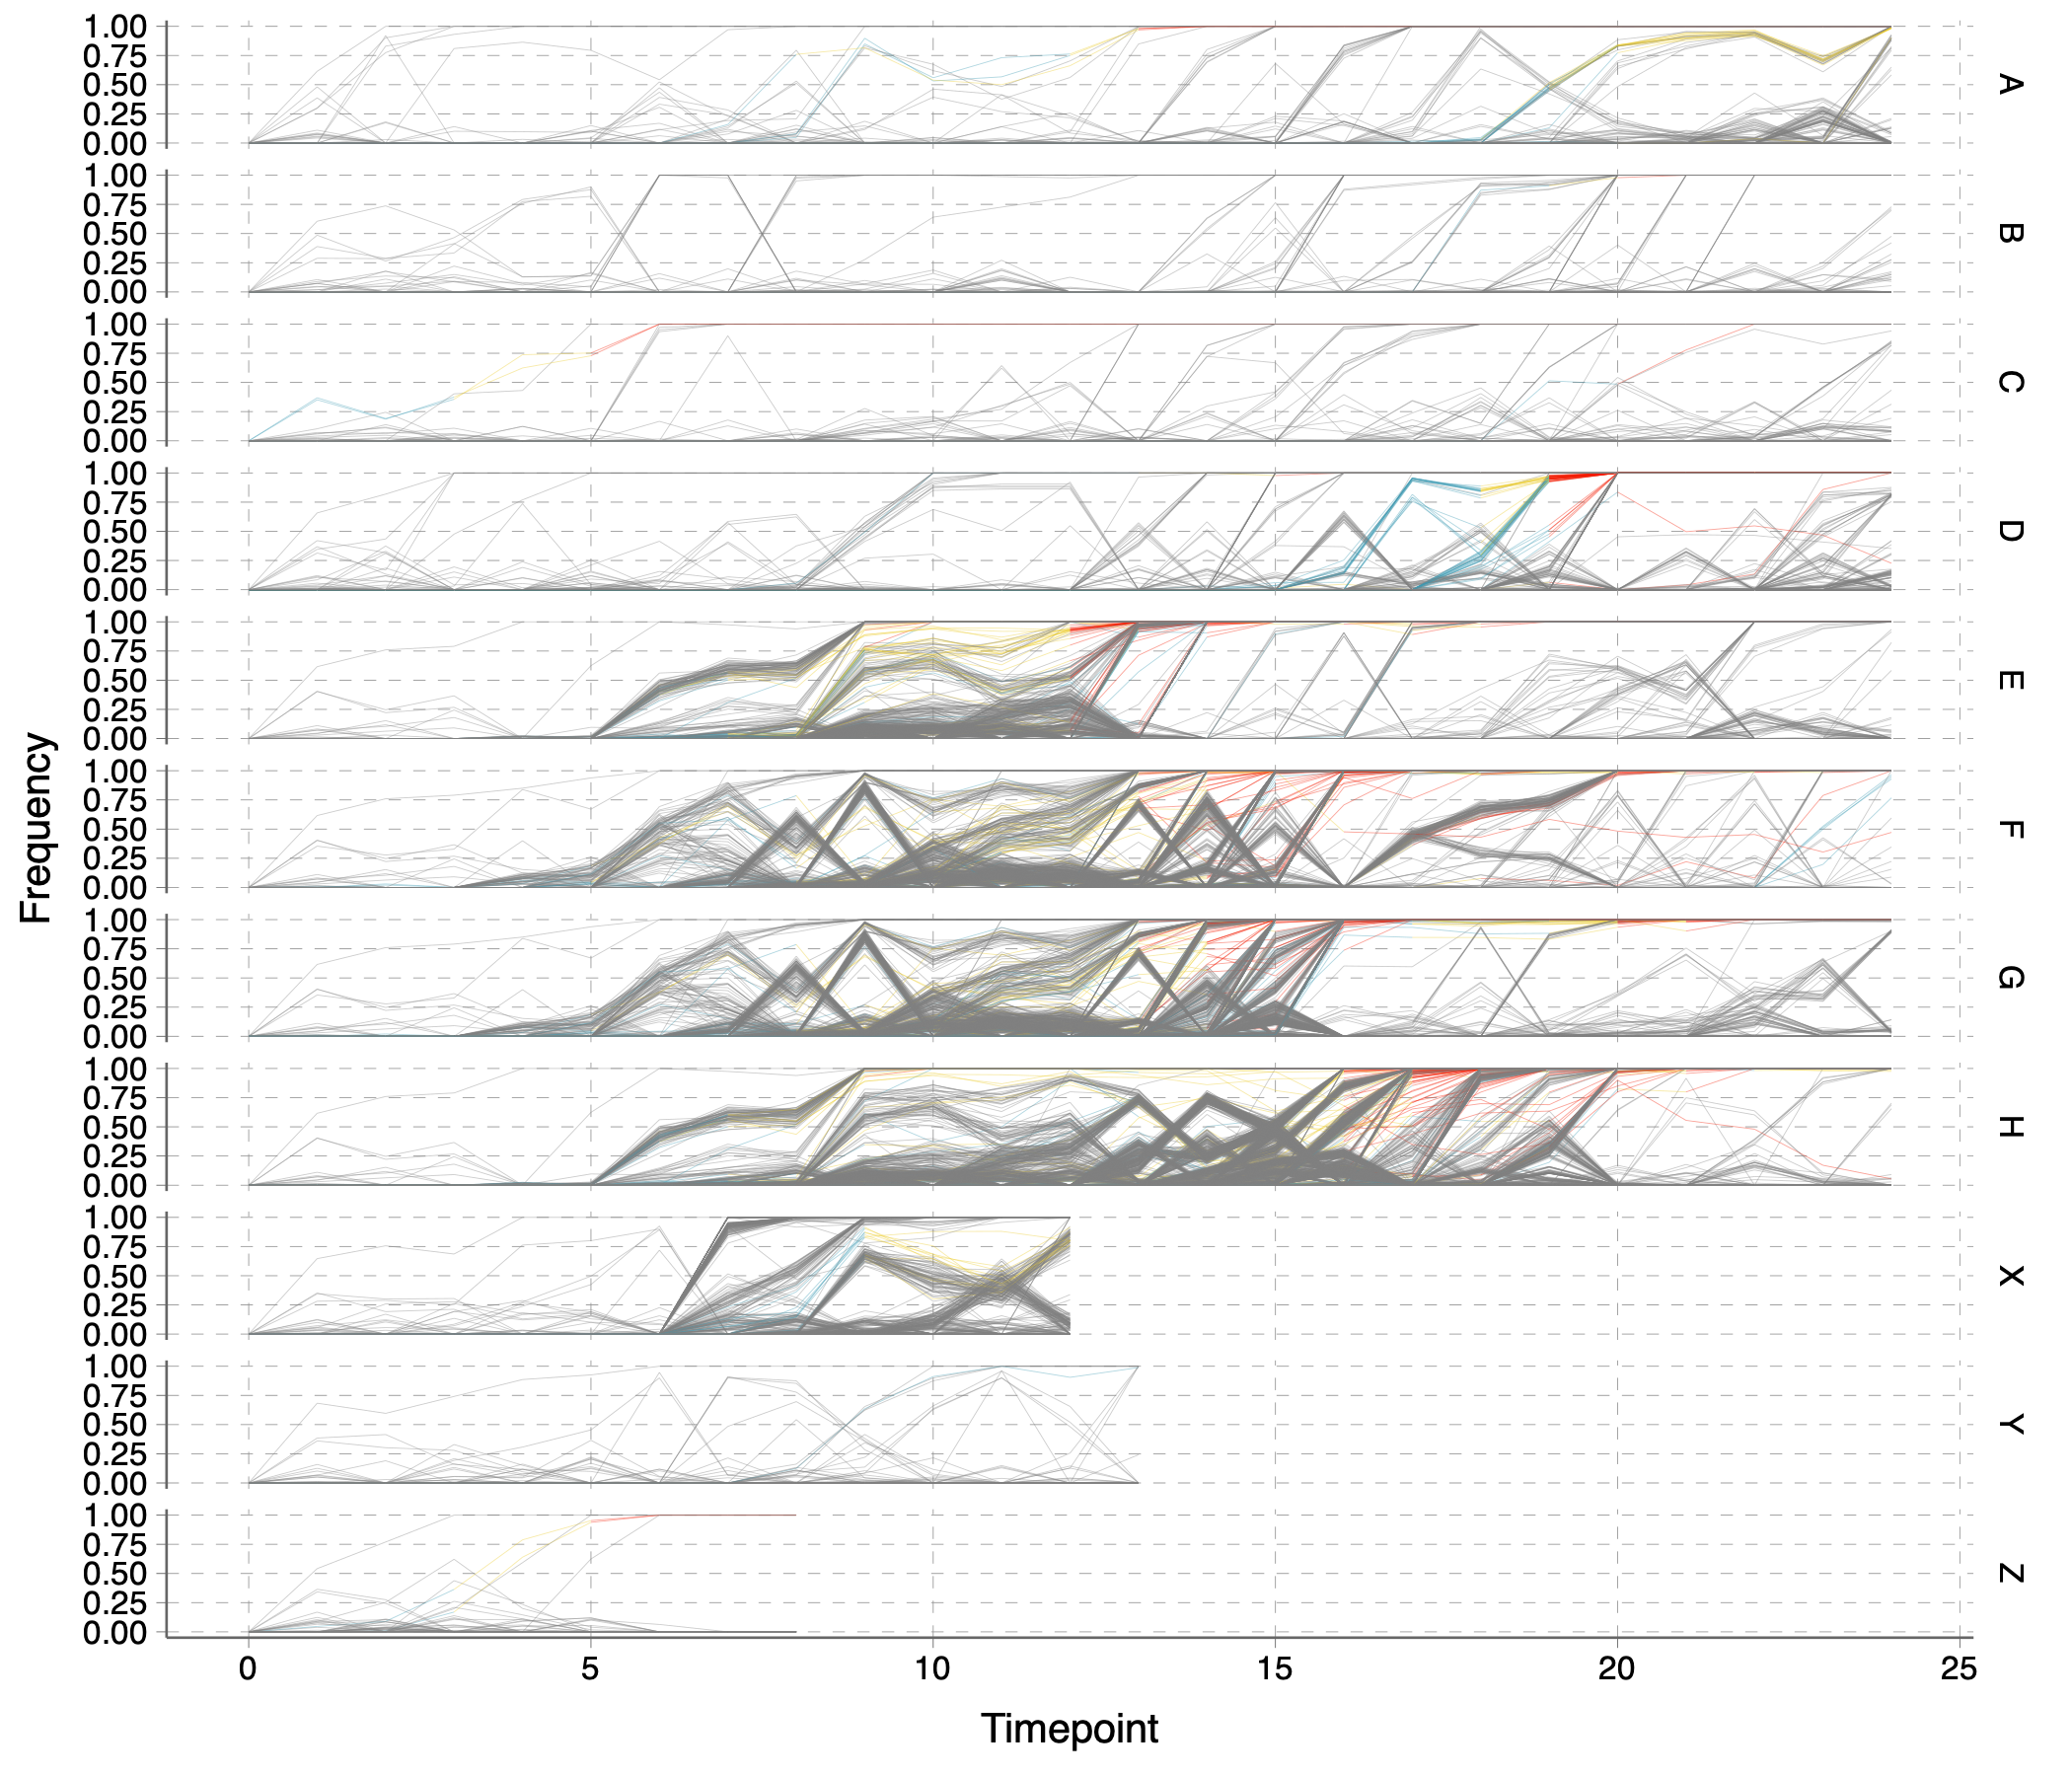

In [15]:
size(6, 7)

# Remove the cross-contamination from H to D at timepoints 6, 9 and 11
d_filtered = d_filtered %>%
    filter(!(
        pop == 'D' &
        any(gen %in% c(6, 9, 11) & freq > 0.1 & freq < 0.75) &
        !any(gen %in% c(5, 7, 8) & freq > 0) &
        !any(gen %in% c(10, 12) & freq > 0.25)
        )) %>%
    ungroup()

d_filtered %>% filter(nchar(pop) == 1) %>% 
fp() + facet_grid(pop ~ .) + nl + aes(col = crosses)

In [16]:
# Final tidy-ing up
min_max_f = 0.1 # remove variants that never reach this frequency

d_filtered =
d_filtered %>%
    select(name, pop, origin, gen, freq, chrom, pos, ref, alt, wave, type, delta, pos_end, locus, rep_len, rep_nt, 
           ad = allele_depth, td = total_depth, edits, crosses, 
           raw_pos, raw_freq, raw_ref, raw_alt, raw_type, read_pop, back_alt, back_delta, collapsed_rows) %>%

    # Recalculate max_f and remove the variants that didn't survive
    group_by(pop, chrom, pos, ref, alt, wave) %>%
    mutate(max_f = max(freq)) %>%
    filter(max_f > 0) %>% 

    # Add the generations of apparition and fixation
    mutate(
        apparition = min(gen[freq > 0]),
        fixation = ifelse(max_f == 1, min(gen[freq == 1]), Inf)
    ) %>% 

    ungroup() %>%
    arrange(pop, chrom, pos, ref, alt, gen, wave)  %>% 

    filter(max_f >= min_max_f)

d_filtered %>% write.tsv('../../../datasets/genomics/03_variant_filtering/results/d_filtered.tsv')